In [14]:
from collections.abc import Callable
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import seaborn as sns
import sys

In [15]:
def plot_bar_metrics(k: int, df: pd.DataFrame) -> None:
    """Строит графики Hit@k и MRR@k для конфигураций из сводной таблицы."""
    data = df.loc[df["k"] == k]
    if data.empty:
        raise ValueError(f"В таблице нет результатов для k={k}")

    experiments = sorted(df["experiment"].unique())
    palette = [
        *plt.get_cmap("tab10").colors,
        *plt.get_cmap("tab20").colors[1::2],
        *plt.get_cmap("tab20b").colors,
    ]
    colors = dict(zip(experiments, sns.color_palette(palette, n_colors=len(experiments))))

    for metric, title in (("hit", "Hit"), ("mrr", "MRR")):
        metric_data = data.loc[data["metric"] == metric]
        positions = range(len(metric_data))
        bar_colors = metric_data["experiment"].map(colors).tolist()
        figure, axes = plt.subplots(
            1, 2,
            figsize=(max(10, 1.5 * len(metric_data)), 4.5),
            sharey=True,
            layout="constrained",
        )
        figure.suptitle(f"{title}@{k}")

        for ax, column, name in zip(axes, ("valid_strict_real", "valid_strict_paraphrase"), ("valid real", "valid paraphrase")):
            bars = ax.bar(positions, metric_data[column], color=bar_colors)
            ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
            ax.set_xticks(positions, metric_data["experiment"], rotation=45, ha="right")
            ax.set_title(name)
            ax.set_ylim(0, 1.12)
            ax.set_axisbelow(True)
            ax.grid(axis="y", alpha=0.25)

    plt.show()


In [16]:
def plot_bar_metrics_real(k: int, df: pd.DataFrame) -> None:
    """Строит рядом Hit@k и MRR@k на оригинальных вопросах."""
    data = df.loc[df["k"] == k]
    if data.empty:
        raise ValueError(f"В таблице нет результатов для k={k}")

    experiments = sorted(df["experiment"].unique())
    palette = [
        *plt.get_cmap("tab10").colors,
        *plt.get_cmap("tab20").colors[1::2],
        *plt.get_cmap("tab20b").colors,
    ]
    colors = dict(zip(experiments, sns.color_palette(palette, n_colors=len(experiments))))
    _, axes = plt.subplots(
        1, 2, figsize=(max(10, 1.5 * len(experiments)), 4.5),
        sharey=True, layout="constrained",
    )

    for ax, (metric, title) in zip(axes, (("hit", "Hit"), ("mrr", "MRR"))):
        metric_data = data.loc[data["metric"] == metric]
        positions = range(len(metric_data))
        bars = ax.bar(
            positions, metric_data["valid_strict_real"],
            color=metric_data["experiment"].map(colors).tolist(),
        )
        ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
        ax.set_xticks(positions, metric_data["experiment"], rotation=45, ha="right")
        ax.set_title(f"{title}@{k}")
        ax.set_ylim(0, 1.12)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)

    plt.show()


In [ ]:
def plot_bar_mrr(k: int, df: pd.DataFrame) -> None:
    """Строит рядом MRR@k на оригинальных вопросах и перефразах."""
    data = df.loc[(df["k"] == k) & (df["metric"] == "mrr")]
    if data.empty:
        raise ValueError(f"В таблице нет MRR для k={k}")

    experiments = sorted(df["experiment"].unique())
    palette = [
        *plt.get_cmap("tab10").colors,
        *plt.get_cmap("tab20").colors[1::2],
        *plt.get_cmap("tab20b").colors,
    ]
    colors = dict(zip(experiments, sns.color_palette(palette, n_colors=len(experiments))))
    bar_colors = data["experiment"].map(colors).tolist()
    positions = range(len(data))

    figure, axes = plt.subplots(
        1, 2, figsize=(max(10, 1.5 * len(data)), 4.5),
        sharey=True, layout="constrained",
    )
    figure.suptitle(f"MRR@{k}")
    for ax, column, name in zip(
        axes,
        ("valid_strict_real", "valid_strict_paraphrase"),
        ("valid real", "valid paraphrase"),
    ):
        bars = ax.bar(positions, data[column], color=bar_colors)
        ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
        ax.set_xticks(positions, data["experiment"], rotation=45, ha="right")
        ax.set_title(name)
        ax.set_ylim(0, 1.12)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)

    plt.show()


In [17]:
def plot_line_metrics(df: pd.DataFrame) -> None:
    """Строит линии Hit@k и MRR@k по всем значениям k в таблице."""
    ks = sorted(df["k"].unique())
    experiments = sorted(df["experiment"].unique())
    palette = [
        *plt.get_cmap("tab10").colors,
        *plt.get_cmap("tab20").colors[1::2],
        *plt.get_cmap("tab20b").colors,
    ]
    colors = dict(zip(experiments, sns.color_palette(palette, n_colors=len(experiments))))

    for metric, title in (("hit", "Hit@k"), ("mrr", "MRR@k")):
        metric_data = df.loc[df["metric"] == metric].sort_values("k")
        figure, axes = plt.subplots(
            1, 2, figsize=(12, 5), sharex=True, sharey=True, layout="constrained",
        )
        figure.suptitle(title)

        for ax, column, name in zip(
            axes,
            ("valid_strict_real", "valid_strict_paraphrase"),
            ("valid real", "valid paraphrase"),
        ):
            for experiment, rows in metric_data.groupby("experiment"):
                ax.plot(
                    rows["k"], rows[column], marker="o",
                    color=colors[experiment], label=experiment,
                )

            ax.set(title=name, xlabel="k", xticks=ks, ylim=(0, 1.05))
            ax.grid(alpha=0.25)

        handles, labels = axes[0].get_legend_handles_labels()
        figure.legend(handles, labels, loc="outside lower center", ncols=5)

    plt.show()


In [18]:
quant_algos = ['ag', 'base', 'bq', 'pq', 'rabitq', 'sq']
dfs: dict[str, pd.DataFrame] = dict.fromkeys(quant_algos)
for algo in quant_algos:
    dfs[algo] = pd.read_csv(f"../results/summary/quant_{algo}.csv")

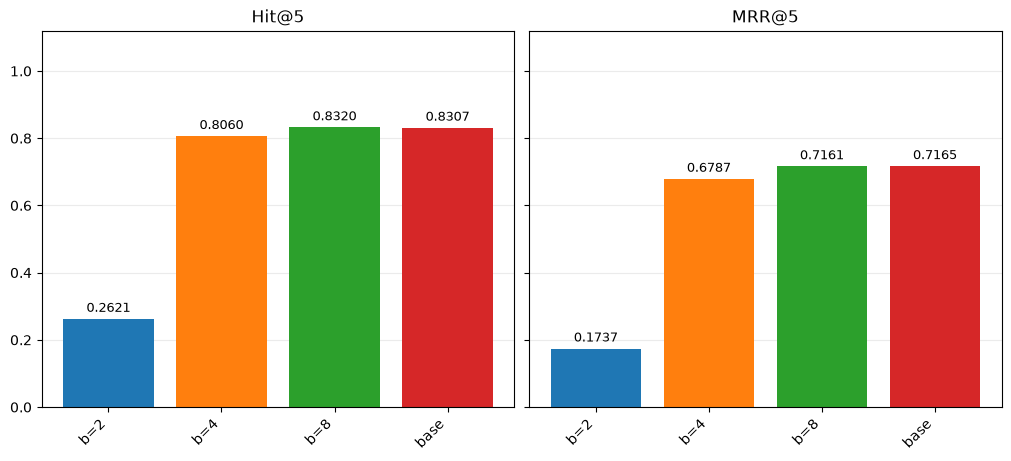

In [19]:
df = pd.read_csv("../results/summary/quant_sq.csv")
df['experiment'] = df['experiment'].apply(lambda x: f"b={x[-1]}")
base = pd.read_csv("../results/summary/quant_base.csv")
df = pd.concat([df, base], ignore_index=True)
plot_bar_metrics_real(k=5, df=df)

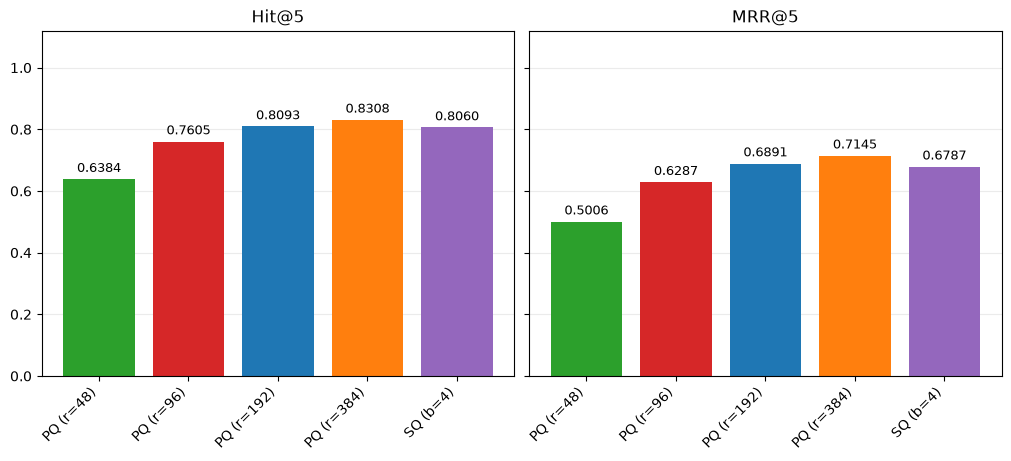

In [20]:
pq = pd.read_csv("../results/summary/quant_pq.csv")
pq4 = pq.loc[pq["num_bits"] == 4].sort_values("num_parts")
pq4["experiment"] = pq4["num_parts"].map(lambda m: f"PQ (r={m})")

sq = pd.read_csv("../results/summary/quant_sq.csv")
sq4 = sq.loc[sq["num_bits"] == 4].assign(experiment="SQ (b=4)")

df = pd.concat([pq4, sq4], ignore_index=True)
plot_bar_metrics_real(k=5, df=df)


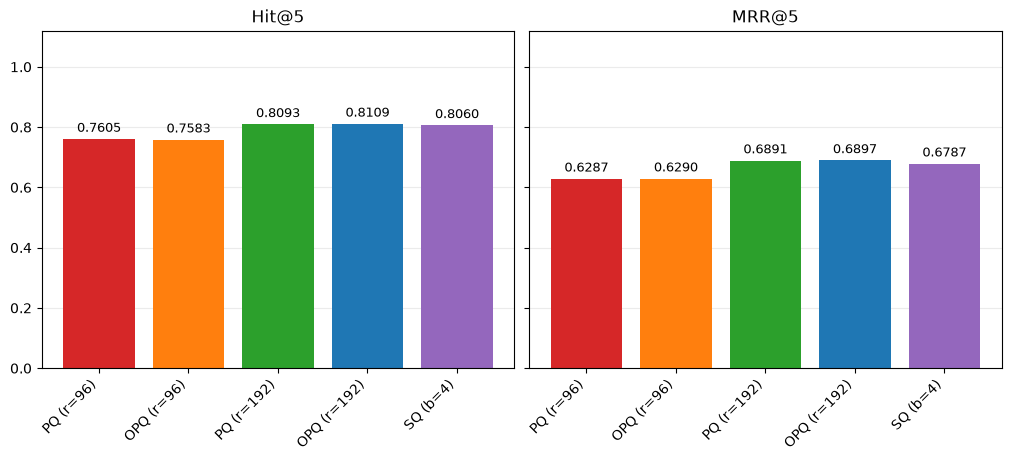

In [21]:
pq = pd.read_csv("../results/summary/quant_pq.csv")
pq4 = pq.loc[(pq["num_bits"] == 4) & pq["num_parts"].isin([96, 192])].copy()
pq4["experiment"] = pq4["num_parts"].map(lambda r: f"PQ (r={r})")

opq = pd.read_csv("../results/summary/quant_opq.csv")
opq4 = opq.loc[(opq["num_bits"] == 4) & opq["num_parts"].isin([96, 192])].copy()
opq4["experiment"] = opq4["num_parts"].map(lambda r: f"OPQ (r={r})")

sq = pd.read_csv("../results/summary/quant_sq.csv")
sq4 = sq.loc[sq["num_bits"] == 4].assign(experiment="SQ (b=4)")

df = pd.concat([pq4, opq4, sq4], ignore_index=True).sort_values("num_parts", kind="stable")
plot_bar_metrics_real(k=5, df=df)


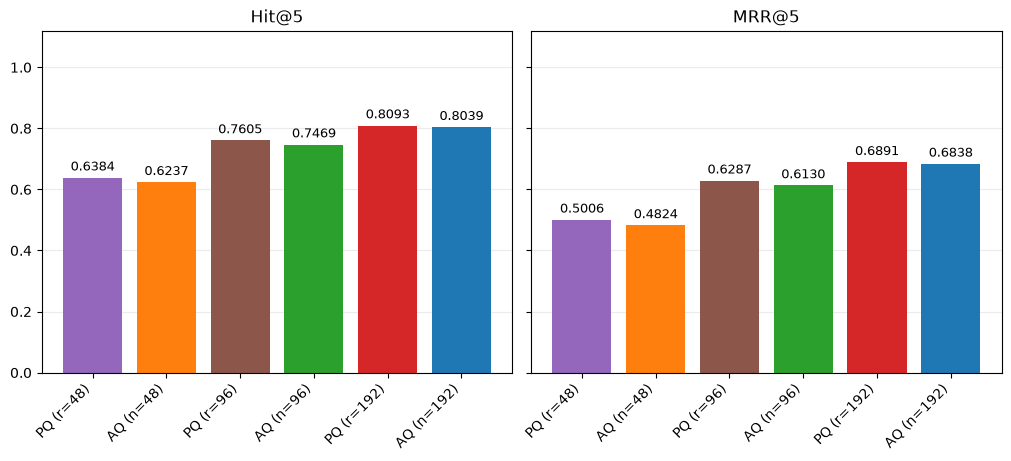

In [27]:
code_sizes = [48, 96, 192]

pq = pd.read_csv("../results/summary/quant_pq.csv")
pq4 = pq.loc[(pq["num_bits"] == 4) & pq["num_parts"].isin(code_sizes)].copy()
pq4["experiment"] = pq4["num_parts"].map(lambda r: f"PQ (r={r})")
pq4["code_bytes"] = pq4["num_parts"] // 2

aq = pd.read_csv("../results/summary/quant_ag.csv")
aq4 = aq.loc[(aq["num_bits"] == 4) & aq["num_codebooks"].isin(code_sizes)].copy()
aq4["experiment"] = aq4["num_codebooks"].map(lambda m: f"AQ (n={m})")
aq4["code_bytes"] = aq4["num_codebooks"] // 2

df = pd.concat([pq4, aq4], ignore_index=True).sort_values("code_bytes", kind="stable")
plot_bar_metrics_real(k=5, df=df)


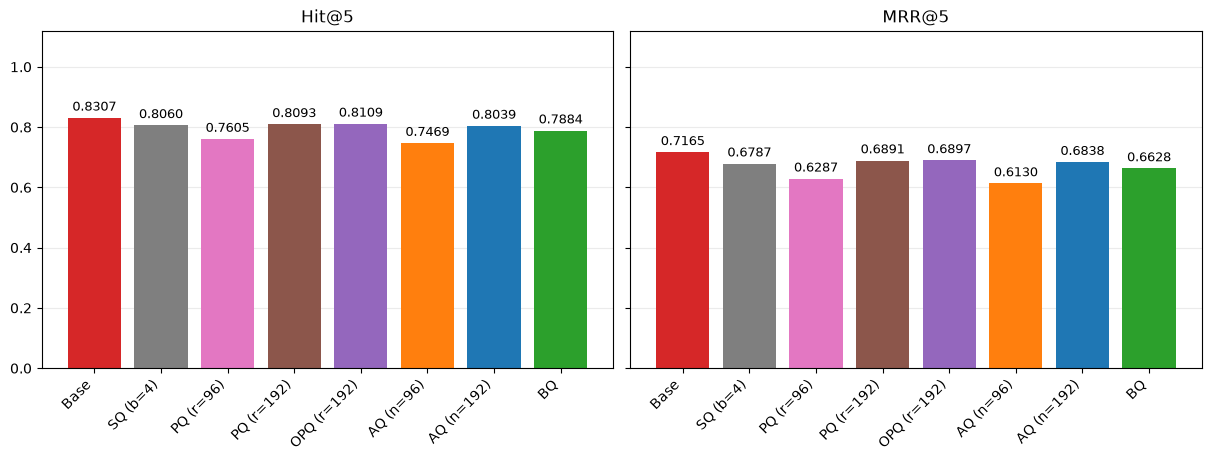

In [ ]:
experiments = {
    "base": "Base",
    "sq4": "SQ (b=4)",
    "pq4_96": "PQ (r=96)",
    "pq4_192": "PQ (r=192)",
    "ag4_96": "AQ (n=96)",
    "ag4_192": "AQ (n=192)",
    "bq": "BQ",
}

results = pd.concat(
    [
        pd.read_csv(f"../results/summary/quant_{algo}.csv")
        for algo in ("base", "sq", "pq", "opq", "ag", "bq")
    ],
    ignore_index=True,
)
bq_comparison = results.set_index("experiment").loc[list(experiments)].reset_index()
bq_comparison["experiment"] = bq_comparison["experiment"].map(experiments)
plot_bar_metrics_real(k=5, df=bq_comparison)


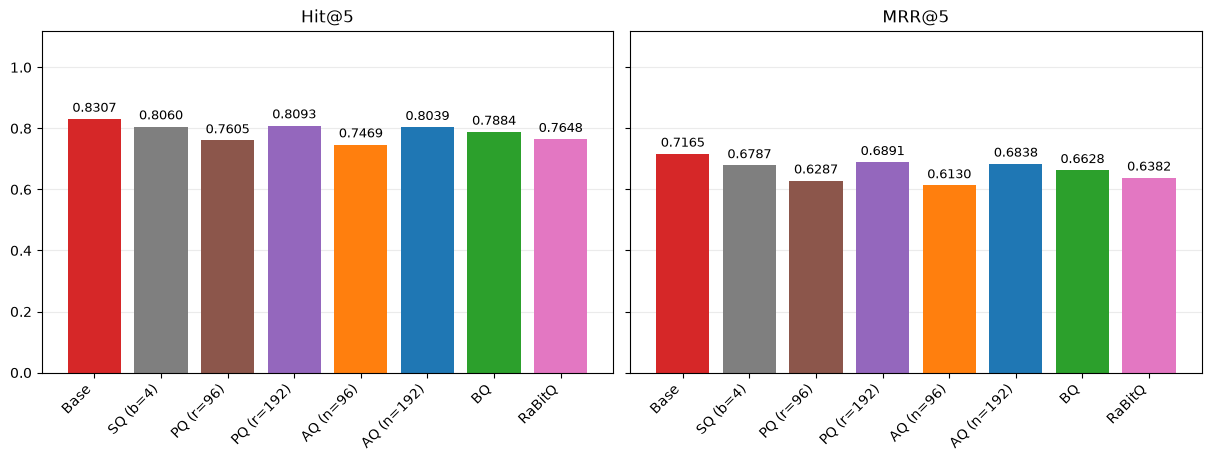

In [ ]:
rabitq = pd.read_csv("../results/summary/quant_rabitq.csv").assign(experiment="RaBitQ")
rabitq_comparison = pd.concat([bq_comparison, rabitq], ignore_index=True)
plot_bar_metrics_real(k=5, df=rabitq_comparison)


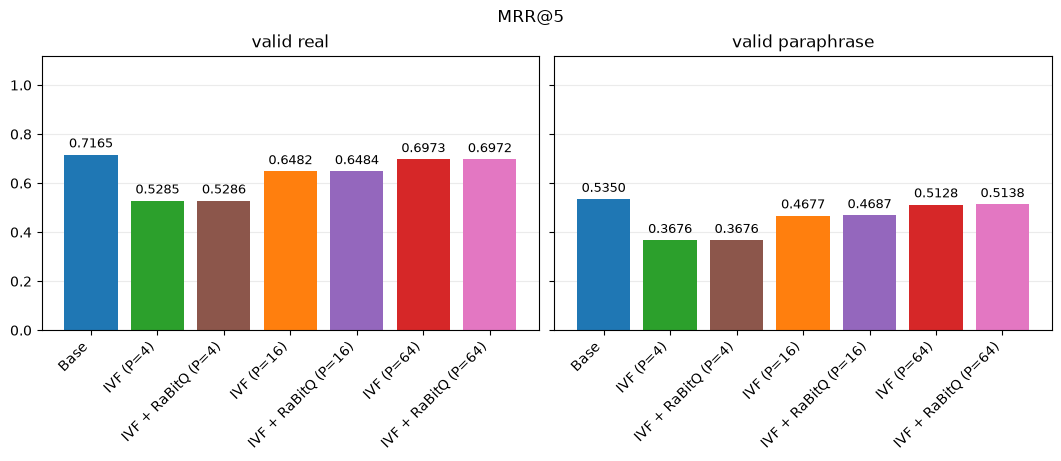

In [ ]:
search_base = pd.read_csv("../results/summary/search_base.csv").assign(experiment="Base")

ivf = pd.read_csv("../results/summary/search_ivf.csv")
ivf["experiment"] = ivf["nprobe"].map(lambda p: f"IVF (P={p})")

ivf_rabitq = pd.read_csv("../results/summary/search_ivf_rabitq.csv")
ivf_rabitq["experiment"] = ivf_rabitq["nprobe"].map(lambda p: f"IVF + RaBitQ (P={p})")

ivf_comparison = pd.concat([search_base, ivf, ivf_rabitq], ignore_index=True)
ivf_comparison = ivf_comparison.sort_values("nprobe", kind="stable", na_position="first")
plot_bar_mrr(k=5, df=ivf_comparison)


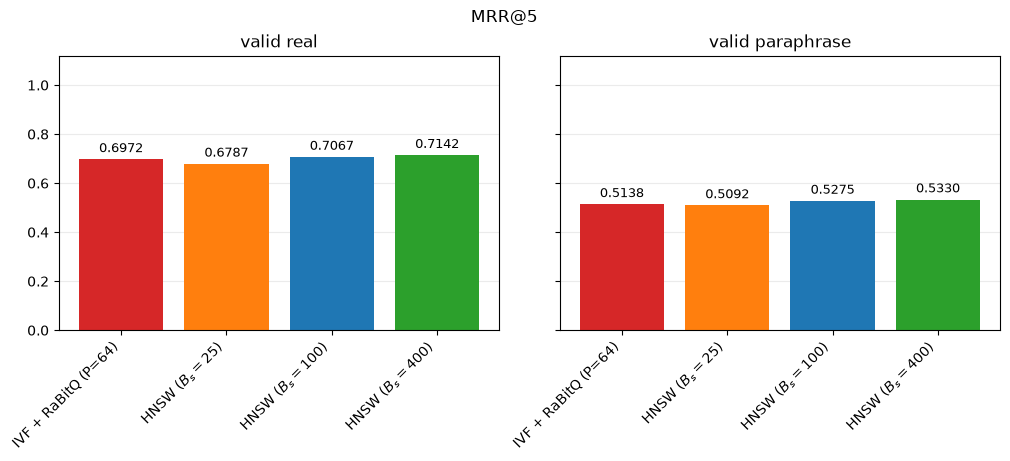

In [ ]:
ivf64 = pd.read_csv("../results/summary/search_ivf_rabitq.csv")
ivf64 = ivf64.loc[ivf64["nprobe"] == 64].assign(experiment="IVF + RaBitQ (P=64)")

hnsw = pd.read_csv("../results/summary/search_hnsw.csv").sort_values("ef_search", kind="stable")
hnsw["experiment"] = hnsw["ef_search"].map(lambda b: f"HNSW ($B_s={b}$)")

hnsw_comparison = pd.concat([ivf64, hnsw], ignore_index=True)
plot_bar_mrr(k=5, df=hnsw_comparison)


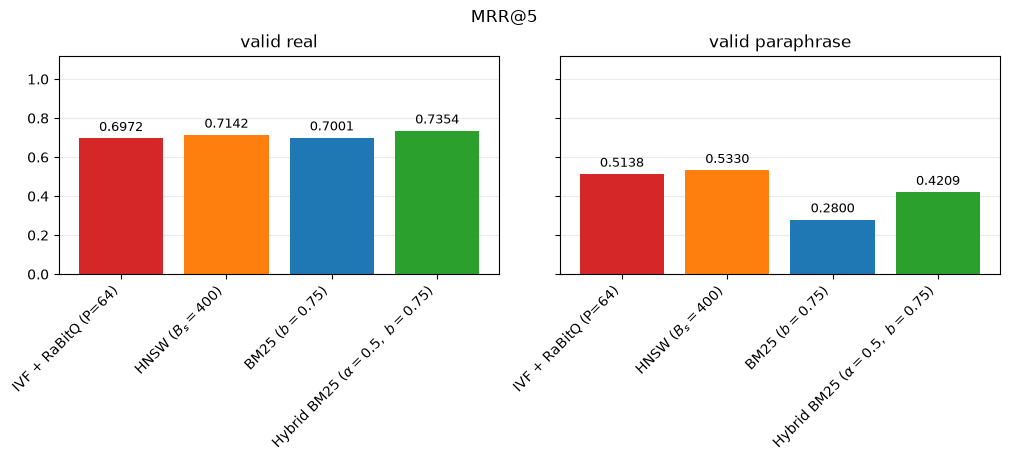

In [ ]:
search_results = []
for file, experiment, label in (
    ("search_ivf_rabitq", "ivf_rabitq_64", "IVF + RaBitQ (P=64)"),
    ("search_hnsw", "hnsw_400", "HNSW ($B_s=400$)"),
    ("search_bm25", "bm25_0.75", "BM25 ($b=0.75$)"),
    ("search_hybrid", "hybrid_0.75_0.5", r"Hybrid BM25 ($\alpha=0.5,\ b=0.75$)"),
):
    table = pd.read_csv(f"../results/summary/{file}.csv")
    search_results.append(table.loc[table["experiment"] == experiment].assign(experiment=label))

search_comparison = pd.concat(search_results, ignore_index=True)
plot_bar_mrr(k=5, df=search_comparison)


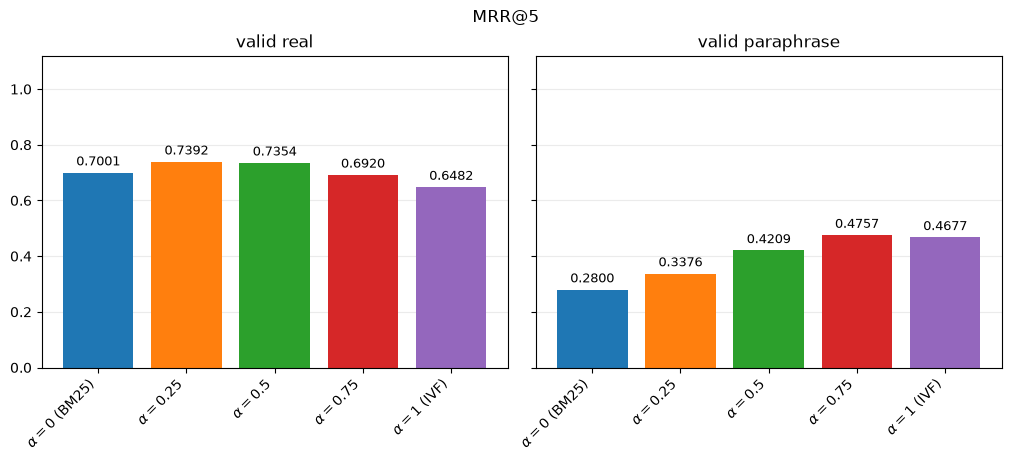

In [ ]:
bm25_zero = pd.read_csv("../results/summary/search_bm25.csv")
bm25_zero = bm25_zero.loc[bm25_zero["b"] == 0.75].assign(experiment=r"$\alpha=0$ (BM25)")

hybrid = pd.read_csv("../results/summary/search_hybrid.csv")
hybrid = hybrid.loc[
    (hybrid["b"] == 0.75) & hybrid["alpha"].isin((0.25, 0.5, 0.75))
].sort_values("alpha", kind="stable")
hybrid["experiment"] = hybrid["alpha"].map(lambda alpha: rf"$\alpha={alpha:g}$")

ivf_one = pd.read_csv("../results/summary/search_ivf.csv")
ivf_one = ivf_one.loc[ivf_one["nprobe"] == 16].assign(experiment=r"$\alpha=1$ (IVF)")

hybrid_comparison = pd.concat([bm25_zero, hybrid, ivf_one], ignore_index=True)
plot_bar_mrr(k=5, df=hybrid_comparison)
